# A2 · Archive: superseded figures

**Status.** Archive. These are figures the paper no longer uses, kept so that they stay reproducible. The paper's own figures are drawn in notebooks 03, 04 and 06. Files here are named for what they show, not by a figure number, so that none can be mistaken for a current figure of the paper.

**Purpose.** Reproduce:

- annual demand: maximum, the two lows and energy (once Fig. 1);
- the heat map of when the lowest half hours occur, over PV capacity (once Fig. 2);
- the low end of the load duration curve (once Fig. 3);
- sunshine and temperature in two panels (once Fig. 4; its left panel is now the paper's Fig. 3);
- the POE bands with three panels, M2, M3 and M4, on the daytime low and on the whole-day minimum (the paper's figure has four panels and shows the daytime low only);
- monthly pinball loss by calendar month, on the daytime low (once Fig. 6) and on the whole-day minimum.

**Inputs**

- `data/interim/network_30min.parquet` from notebook 01.
- `data/interim/pv_annual.parquet` and `weather_daily.parquet` from notebook 02.
- `data/interim/forecasts.parquet` from notebook 05.

**Outputs** (`outputs/archive`; each figure as PNG at 600 dpi and PDF)

- `annual_max_lows_energy` and `annual_max_lows_energy_data.csv`.
- `low_hours_heatmap` and `low_hours_heatmap_data.csv`.
- `load_duration_low_end`.
- `solar_and_temperature`.
- `poe_bands_three_panels_daytime_low` and `poe_bands_three_panels_minimum`.
- `monthly_pinball_daytime_low` and `monthly_pinball_minimum`, each with its `_data.csv`.

**Main process**

1. Set up.
2. Annual demand: maximum, the two lows and energy.
3. When the lowest half hours occur.
4. The low end of the load duration curve.
5. Sunshine and temperature.
6. POE bands with three panels.
7. Monthly pinball loss by calendar month.
8. Result.

Run notebooks 01, 02 and 05 first.

## 1. Set up

In [1]:
import pandas as pd

from pynmdf import evaluate, plots, targets
from pynmdf.config import load_config

cfg = load_config()
interim, archive = cfg["dirs"]["interim"], cfg["dirs"]["archive"]
windows = cfg["targets"]["troughs"]
selected_years = cfg["figures"]["selected_years"]
plots.set_style()

pd.set_option("display.width", 220, "display.max_columns", 30)
pd.set_option("display.float_format", "{:,.0f}".format)
total = pd.read_parquet(interim / "network_30min.parquet")["total_mw"]
capacity = pd.read_parquet(interim / "pv_annual.parquet")["kwp"]
weather = pd.read_parquet(interim / "weather_daily.parquet")
forecasts = pd.read_parquet(interim / "forecasts.parquet")

# The two targets, with the y-axis label each takes in the POE-band figure.
TARGETS = {"daytime_low": "Annual daytime low (MW)", "minimum": "Annual minimum (MW)"}

## 2. Annual demand: maximum, the two lows and energy

Maximum demand, the overnight low and the daytime low are lines on the left axis (MW); annual energy is bars on the right axis (GWh). The two scales are aligned so that 1,000 MW sits level with 10,000 GWh. Energy allows for gaps: the mean of the valid half hours times the hours in the year.

The paper's Fig. 1 now shows the two lows over PV capacity; the maximum and the energy are kept as a check in `outputs/checks/check_annual_summary.csv`.

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
max_mw,"4,633","4,717","5,269","4,676","5,146","5,066","4,459","4,226","4,757","4,679","4,607"
overnight_low_mw,"1,368","1,433","1,474","1,495","1,473","1,429","1,388","1,428","1,393","1,420","1,435"
daytime_low_mw,"1,833","1,891","1,888","1,902","1,759","1,671","1,357","1,458","1,080","1,019",880
energy_gwh,"21,444","22,013","22,386","22,291","21,931","20,927","19,805","20,175","19,287","19,685","19,872"


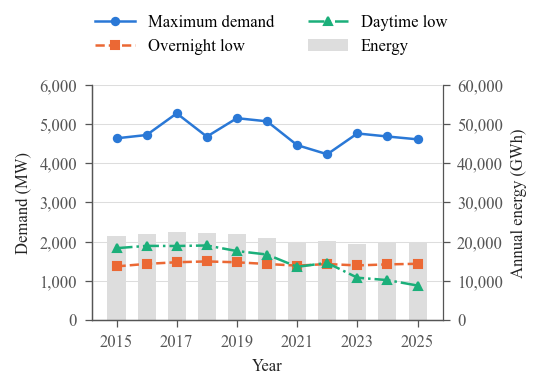

In [2]:
annual = targets.annual_summary(total).join(targets.annual_window_lows(total, windows))
plotted = annual[["max_mw", "overnight_low_mw", "daytime_low_mw", "energy_gwh"]]
plotted.to_csv(archive / "annual_max_lows_energy_data.csv")

figure = plots.annual_demand(annual)
plots.save_figure(figure, archive, "annual_max_lows_energy")
plotted.T

## 3. When the lowest half hours occur

Take the lowest 1% of each year's valid half hours and count how many start in each clock hour. The heat map shows that share by year and hour; the bars beneath show PV capacity at 30 June. Times are local clock time.

The table is the figure's data: each column sums to 100. The share falling in the daytime window is kept as a check in `outputs/checks/check_low_hours.csv`.

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
year,,,,,,,,,,,,,,,,,,,,,,,,
2015,0,0,1,24,48,27,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2016,0,0,0,27,46,23,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2017,0,0,1,25,49,22,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2018,0,0,0,26,49,21,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2019,0,0,0,27,49,22,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2020,0,0,1,23,46,28,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2021,0,0,0,17,43,19,2,0,0,0,4,5,3,3,3,2,0,0,0,0,0,0,0,0
2022,0,0,4,21,29,16,2,1,0,1,2,5,5,8,5,1,0,0,0,0,0,0,0,0
2023,0,0,0,0,0,0,0,1,2,5,13,22,22,21,12,2,0,0,0,0,0,0,0,0


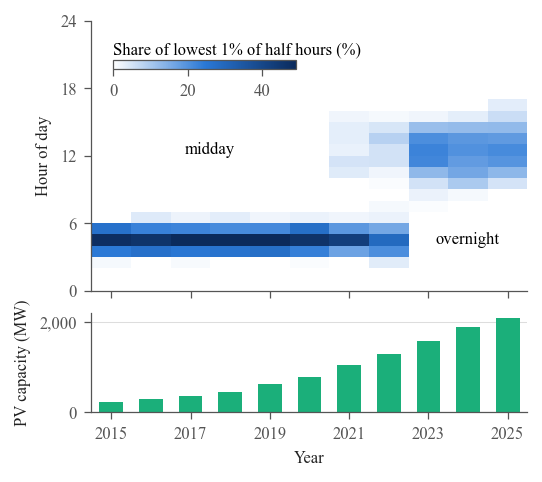

In [3]:
lowest = targets.lowest_intervals(total, cfg["figures"]["low_share"])
hour_shares = targets.low_hour_shares(lowest)
hour_shares.to_csv(archive / "low_hours_heatmap_data.csv")

figure = plots.low_hours_heatmap(hour_shares, capacity)
plots.save_figure(figure, archive, "low_hours_heatmap")
hour_shares.round().astype(int).T

## 4. The low end of the load duration curve

The same lowest 1% of half hours, sorted from the lowest, for three years. The marker at the left end is the year's absolute minimum. The table gives the two ends of each curve.

year,2015,2020,2025
minimum_mw,"1,368","1,429",880
at_1pct_mw,"1,465","1,523","1,236"


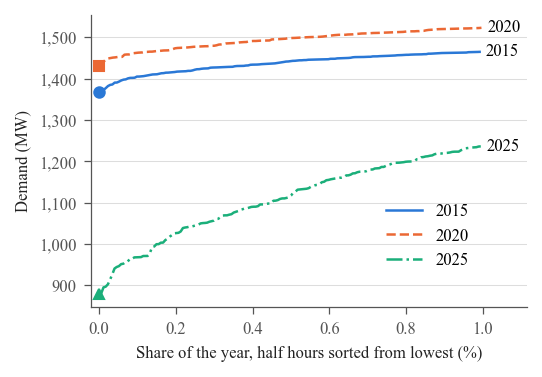

In [4]:
figure = plots.low_duration(lowest, selected_years)
plots.save_figure(figure, archive, "load_duration_low_end")

curves = lowest[lowest["year"].isin(selected_years)].groupby("year")["mw"]
pd.DataFrame({"minimum_mw": curves.min(), "at_1pct_mw": curves.max()}).T

## 5. Sunshine and temperature

Each point is one day, for three years. The left panel plots the day's daytime low against that day's solar exposure, with a least-squares line per year; the right panel plots the day's minimum against its mean temperature. Only days on which both trough windows are complete are used.

The left panel, drawn larger and on its own, is now the paper's Fig. 3 (notebook 04).

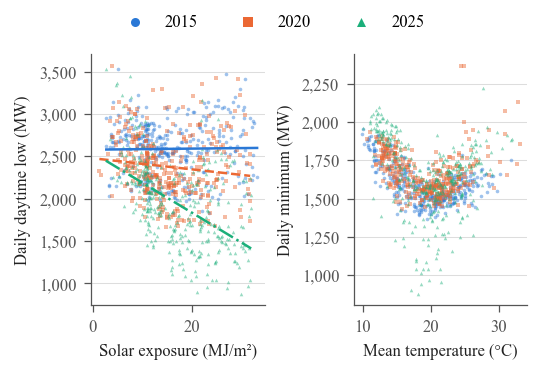

In [5]:
daily = pd.concat(
    [
        targets.daily_minimum(total),
        targets.daily_troughs(total, windows)["daytime"],
        weather[["solar", "tmean"]],
    ],
    axis=1,
    join="inner",
)
solar_fits = targets.yearly_line_fits(daily, "solar", "daytime", selected_years)

figure = plots.solar_and_temperature(daily, solar_fits)
plots.save_figure(figure, archive, "solar_and_temperature")

## 6. POE bands with three panels

Three panels on one y-axis: M2 (time trend, no PV), M3 (PV only) and M4 (PV plus weather). The shaded band runs from POE90 to POE10, the line is POE50 and the dots are the actual values. One figure per target.

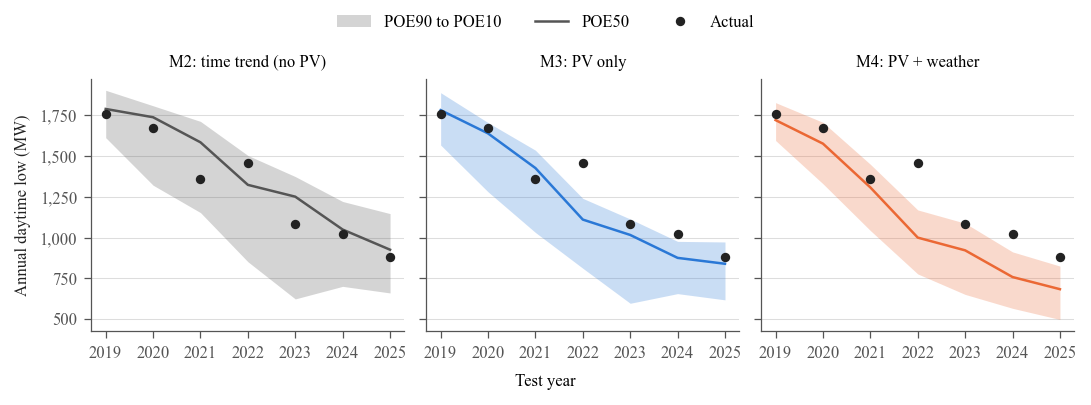

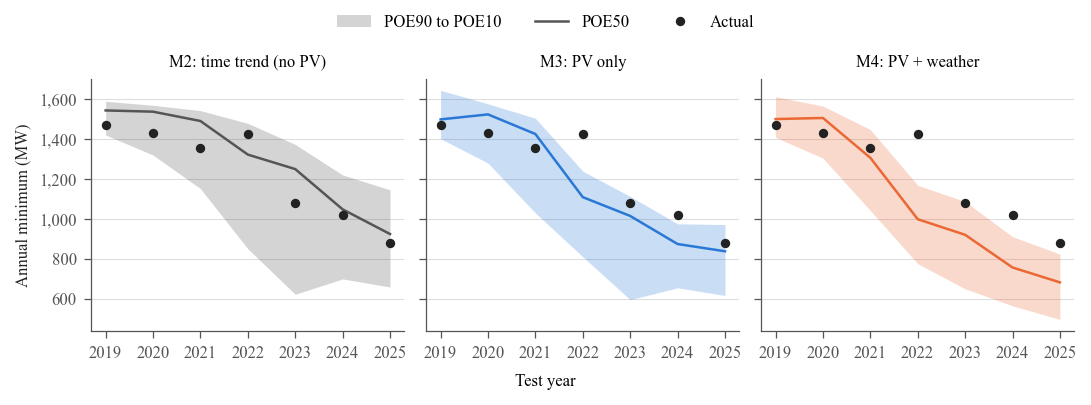

In [6]:
for target, ylabel in TARGETS.items():
    annual_forecasts = forecasts[(forecasts["target"] == target) & (forecasts["level"] == "annual")]
    figure = plots.poe_bands(annual_forecasts, ["M2", "M3", "M4"], ylabel)
    plots.save_figure(figure, archive, f"poe_bands_three_panels_{target}")

## 7. Monthly pinball loss by calendar month

The monthly forecasts scored separately for each calendar month, for M3, M4 and M5, once for each target. Each point is the mean pinball loss over that month's valid test years (seven at most), so single months are noisy.

The tables are the figures' data; the saved CSVs hold all six models.

Daytime low (MW)


month,1,2,3,4,5,6,7,8,9,10,11,12
model,,,,,,,,,,,,
M1,41,50,76,42,45,39,48,41,41,60,69,55
M2,81,79,60,63,40,43,46,45,41,50,45,49
M3,69,56,57,51,39,36,59,37,38,38,54,58
M4,58,54,57,34,45,42,80,41,50,31,63,59
M5,33,57,36,34,48,38,47,38,34,64,57,33
M6,62,69,77,63,75,72,79,99,85,136,64,36


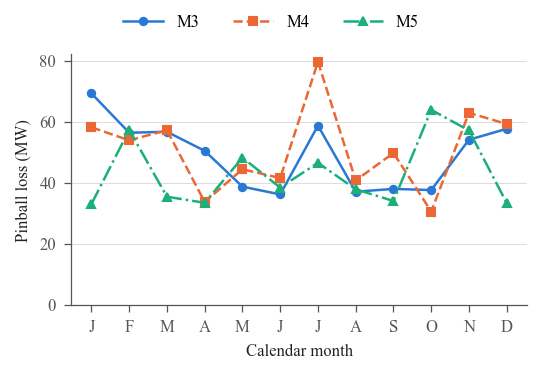

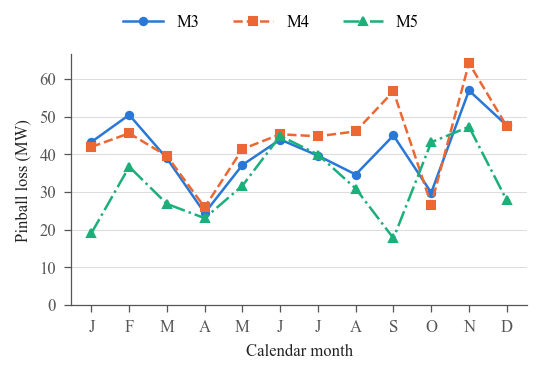

In [7]:
by_month = {}
for target in TARGETS:
    rows = forecasts[(forecasts["target"] == target) & (forecasts["level"] == "monthly")]
    by_month[target] = evaluate.score(rows, ["model", "month"])
    by_month[target].to_csv(archive / f"monthly_pinball_{target}_data.csv")
    figure = plots.monthly_pinball(by_month[target], ["M3", "M4", "M5"])
    plots.save_figure(figure, archive, f"monthly_pinball_{target}")

print("Daytime low (MW)")
by_month["daytime_low"]["pinball_mean"].unstack("month").round()

In [8]:
print("Whole-day minimum (MW)")
by_month["minimum"]["pinball_mean"].unstack("month").round()

Whole-day minimum (MW)


month,1,2,3,4,5,6,7,8,9,10,11,12
model,,,,,,,,,,,,
M1,25,46,42,27,26,46,45,42,48,50,72,54
M2,44,54,35,31,29,40,32,36,35,38,37,37
M3,43,50,39,24,37,44,40,35,45,30,57,48
M4,42,46,40,26,41,45,45,46,57,27,64,47
M5,19,37,27,23,32,45,40,31,18,43,47,28
M6,27,28,44,26,41,62,57,52,34,76,40,24


## 8. Result

The figures this notebook wrote to the archive.

In [9]:
written = [
    "annual_max_lows_energy",
    "low_hours_heatmap",
    "load_duration_low_end",
    "solar_and_temperature",
    "poe_bands_three_panels_daytime_low",
    "poe_bands_three_panels_minimum",
    "monthly_pinball_daytime_low",
    "monthly_pinball_minimum",
]
for name in written:
    for suffix in (".png", ".pdf"):
        assert (archive / f"{name}{suffix}").exists(), name
print(f"{len(written)} superseded figures in outputs/archive:")
print("\n".join(written))

8 superseded figures in outputs/archive:
annual_max_lows_energy
low_hours_heatmap
load_duration_low_end
solar_and_temperature
poe_bands_three_panels_daytime_low
poe_bands_three_panels_minimum
monthly_pinball_daytime_low
monthly_pinball_minimum
